# TransUNet on Kvasir-SEG — Polyp Segmentation

This notebook trains **TransUNet** (CNN + Vision Transformer hybrid encoder, U-Net-style decoder)
on the **Kvasir-SEG** dataset and reports:

- **DSC** (Dice Similarity Coefficient)
- **IoU** (Intersection over Union)
- **F1 score**
- **Pixel Accuracy**

Dataset: https://www.kaggle.com/datasets/debeshjha1/kvasirseg

**How to run**
1. Runtime → Change runtime type → GPU (T4 or better).
2. Run the cells top to bottom.
3. In the "Download dataset" cell you'll be asked to upload your `kaggle.json` API token
   (Kaggle → Account → Create New API Token). Alternatively, upload/mount the dataset yourself
   and skip that cell — just make sure the final folder structure is:
   ```
   Kvasir-SEG/
       images/*.jpg
       masks/*.jpg
   ```
Everything (image size, batch size, epochs, model depth, etc.) is exposed in the **Config** cell
so you can edit it freely.


## 1. Install dependencies

In [ ]:
!pip install -q timm albumentations opencv-python-headless kaggle


In [ ]:
pip install -q kagglehub

In [ ]:
import os
import kagglehub

# Determine the actual data root for the Kvasir-SEG dataset.
# The `kagglehub.dataset_download` typically mounts the dataset
# to a read-only path like /kaggle/input/dataset_name.
# The internal structure might be nested.

data_root_found = None
download_base_path = None

try:
    print("Attempting to download/locate Kvasir-SEG dataset using kagglehub...")
    download_base_path = kagglehub.dataset_download("debeshjha1/kvasirseg")
    print(f"KaggleHub provided base path: {download_base_path}")

    # Check for the most common nested structure observed in Kaggle datasets:
    # /kaggle/input/kvasirseg/Kvasir-SEG/Kvasir-SEG
    potential_path_1 = os.path.join(download_base_path, 'Kvasir-SEG', 'Kvasir-SEG')
    # Check for direct structure: /kaggle/input/kvasirseg/Kvasir-SEG
    potential_path_2 = os.path.join(download_base_path, 'Kvasir-SEG')
    # Check for case where dataset name is the direct folder: /kaggle/input/kvasirseg/kvasirseg
    potential_path_3 = os.path.join(download_base_path, 'kvasirseg')
    # Check if the base path itself contains images/masks directly
    potential_path_4 = download_base_path

    for path_candidate in [potential_path_1, potential_path_2, potential_path_3, potential_path_4]:
        if path_candidate and os.path.exists(path_candidate) and \
           os.path.isdir(path_candidate) and \
           os.path.exists(os.path.join(path_candidate, 'images')) and \
           os.path.exists(os.path.join(path_candidate, 'masks')):
            data_root_found = path_candidate
            print(f"Identified Kvasir-SEG data root: {data_root_found}")
            break

    if not data_root_found:
        print(f"Could not automatically identify Kvasir-SEG data root within {download_base_path}.")
        print(f"Contents of {download_base_path}: {os.listdir(download_base_path)}")
        # If still not found, try to locate Kvasir-SEG folder recursively
        for root, dirs, files in os.walk(download_base_path):
            if 'images' in dirs and 'masks' in dirs:
                data_root_found = root
                print(f"Found Kvasir-SEG data root by recursive search: {data_root_found}")
                break

    if not data_root_found:
        raise FileNotFoundError("Kvasir-SEG dataset directory not found in expected structure.")

except Exception as e:
    print(f"Error during kagglehub download/locating: {e}")
    print("Falling back to checking current directory for Kvasir-SEG.")
    if os.path.exists('Kvasir-SEG') and os.path.isdir('Kvasir-SEG'):
        data_root_found = 'Kvasir-SEG'
        print("Found Kvasir-SEG in current working directory.")
    else:
        raise FileNotFoundError("Kvasir-SEG dataset directory not found. Please ensure it's available.")

# Update the data_dir in the CFG object
if data_root_found:
    cfg.data_dir = data_root_found
    print(f"cfg.data_dir has been updated to: {cfg.data_dir}")
    print(f"Contents of {cfg.data_dir}: {os.listdir(cfg.data_dir)}")
else:
    print("Failed to set cfg.data_dir.")


Attempting to download/locate Kvasir-SEG dataset using kagglehub...
Using Colab cache for faster access to the 'kvasirseg' dataset.
KaggleHub provided base path: /kaggle/input/kvasirseg
Identified Kvasir-SEG data root: /kaggle/input/kvasirseg/Kvasir-SEG/Kvasir-SEG
cfg.data_dir has been updated to: /kaggle/input/kvasirseg/Kvasir-SEG/Kvasir-SEG
Contents of /kaggle/input/kvasirseg/Kvasir-SEG/Kvasir-SEG: ['annotated_images', 'bbox', 'images', '1911.07069.pdf', 'masks']


## 2. Download the Kvasir-SEG dataset

Run this cell and upload your `kaggle.json` when prompted. Get it from
Kaggle → Settings → API → **Create New API Token**.

If you already have the dataset (e.g. uploaded manually or mounted from Drive) in the structure
`Kvasir-SEG/images/*.jpg`, `Kvasir-SEG/masks/*.jpg`, you can skip running this cell.


In [ ]:
import os

if not os.path.exists('Kvasir-SEG'):
    from google.colab import files
    print("Please upload your kaggle.json file:")
    uploaded = files.upload()  # upload kaggle.json here

    os.makedirs('/root/.kaggle', exist_ok=True)
    for fname in uploaded.keys():
        if fname == 'kaggle.json':
            with open('/root/.kaggle/kaggle.json', 'wb') as f:
                f.write(uploaded[fname])
    os.system('chmod 600 /root/.kaggle/kaggle.json')

    !kaggle datasets download -d debeshjha1/kvasirseg
    !unzip -q kvasirseg.zip -d .
    # The zip usually extracts to 'Kvasir-SEG'; handle nested folder cases just in case
    if not os.path.exists('Kvasir-SEG') and os.path.exists('kvasir-seg'):
        os.rename('kvasir-seg', 'Kvasir-SEG')
else:
    print("Kvasir-SEG folder already exists, skipping download.")

print(os.listdir('Kvasir-SEG'))


Please upload your kaggle.json file:


KeyboardInterrupt: 

## 3. Imports

In [ ]:
import os
import cv2
import glob
import time
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)


Using device: cuda


## 4. Config — edit hyperparameters here

In [ ]:
class CFG:
    data_dir      = "Kvasir-SEG"
    img_size      = 224          # TransUNet default patch grid works well with 224
    batch_size    = 8
    num_workers   = 2
    epochs        = 40
    lr            = 1e-4
    weight_decay  = 1e-5
    val_split     = 0.15
    test_split    = 0.15
    vit_backbone  = "vit_base_patch16_224"  # timm ViT used as the transformer bridge
    embed_dim     = 768
    num_heads     = 12
    transformer_layers = 6        # number of transformer blocks in the bridge
    mlp_ratio     = 4
    dropout       = 0.1
    threshold     = 0.5           # binarization threshold for metrics
    ckpt_path     = "transunet_kvasir_best.pth"

cfg = CFG()


## 5. Dataset & augmentations

Found 1000 image/mask pairs
Train: 700  Val: 150  Test: 150


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


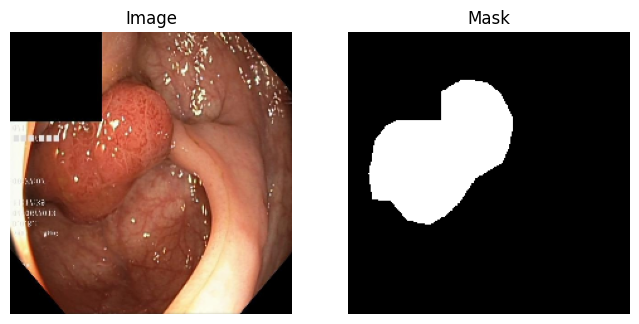

In [ ]:
image_paths = sorted(glob.glob(os.path.join(cfg.data_dir, "images", "*.jpg")))
mask_paths  = sorted(glob.glob(os.path.join(cfg.data_dir, "masks", "*.jpg")))
assert len(image_paths) == len(mask_paths) and len(image_paths) > 0, "Check dataset paths!"
print(f"Found {len(image_paths)} image/mask pairs")

train_imgs, temp_imgs, train_masks, temp_masks = train_test_split(
    image_paths, mask_paths, test_size=(cfg.val_split + cfg.test_split), random_state=SEED
)
rel_test = cfg.test_split / (cfg.val_split + cfg.test_split)
val_imgs, test_imgs, val_masks, test_masks = train_test_split(
    temp_imgs, temp_masks, test_size=rel_test, random_state=SEED
)
print(f"Train: {len(train_imgs)}  Val: {len(val_imgs)}  Test: {len(test_imgs)}")

train_tf = A.Compose([
    A.Resize(cfg.img_size, cfg.img_size),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

eval_tf = A.Compose([
    A.Resize(cfg.img_size, cfg.img_size),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])


class KvasirDataset(Dataset):
    def __init__(self, images, masks, transform=None):
        self.images = images
        self.masks = masks
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = cv2.imread(self.images[idx])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(self.masks[idx], cv2.IMREAD_GRAYSCALE)
        mask = (mask > 127).astype(np.float32)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        mask = mask.unsqueeze(0).float() if mask.ndim == 2 else mask.float()
        return image, mask


train_ds = KvasirDataset(train_imgs, train_masks, transform=train_tf)
val_ds   = KvasirDataset(val_imgs, val_masks, transform=eval_tf)
test_ds  = KvasirDataset(test_imgs, test_masks, transform=eval_tf)

train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True,
                           num_workers=cfg.num_workers, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds, batch_size=cfg.batch_size, shuffle=False,
                           num_workers=cfg.num_workers, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=cfg.batch_size, shuffle=False,
                           num_workers=cfg.num_workers, pin_memory=True)

# Quick visual sanity check
img, msk = train_ds[0]
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
mean = np.array([0.485, 0.456, 0.406]); std = np.array([0.229, 0.224, 0.225])
disp_img = (img.permute(1, 2, 0).numpy() * std + mean).clip(0, 1)
ax[0].imshow(disp_img); ax[0].set_title("Image"); ax[0].axis('off')
ax[1].imshow(msk.squeeze(), cmap='gray'); ax[1].set_title("Mask"); ax[1].axis('off')
plt.show()

## 6. TransUNet architecture

Faithful compact implementation of TransUNet (Chen et al., 2021):

- **CNN encoder** (ResNet-50, ImageNet-pretrained) produces multi-scale feature maps.
  The 3 shallow stages are kept as **skip connections**; the deepest feature map is fed to the transformer.
- **Transformer bridge**: the deepest CNN feature map is flattened into patch tokens,
  given learnable positional embeddings, and passed through `transformer_layers` standard
  Transformer encoder blocks (multi-head self-attention + MLP), exactly as in ViT.
- **Cascaded Upsampler (CUP) decoder**: the transformer output is reshaped back to a spatial
  grid and progressively upsampled with conv blocks, fusing the CNN skip connections at each
  stage (U-Net style), ending in a 1-channel segmentation map.


In [ ]:
import torchvision


class TransformerBlock(nn.Module):
    def __init__(self, dim, num_heads, mlp_ratio=4, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, num_heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim * mlp_ratio, dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        residual = x
        x = self.norm1(x)
        attn_out, _ = self.attn(x, x, x)
        x = residual + attn_out
        x = x + self.mlp(self.norm2(x))
        return x


class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class DecoderBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv = ConvBlock(in_ch + skip_ch, out_ch)

    def forward(self, x, skip=None):
        x = self.up(x)
        if skip is not None:
            if x.shape[-2:] != skip.shape[-2:]:
                x = F.interpolate(x, size=skip.shape[-2:], mode='bilinear', align_corners=True)
            x = torch.cat([x, skip], dim=1)
        return self.conv(x)


class TransUNet(nn.Module):
    """
    CNN (ResNet-50) encoder -> Transformer bridge -> CUP decoder -> segmentation map.
    Input:  (B, 3, H, W)
    Output: (B, 1, H, W) raw logits
    """
    def __init__(self, img_size=224, embed_dim=768, num_heads=12,
                 transformer_layers=6, mlp_ratio=4, dropout=0.1, num_classes=1):
        super().__init__()
        resnet = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)

        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)   # /2   -> 64 ch
        self.pool = resnet.maxpool                                        # /4
        self.layer1 = resnet.layer1                                       # /4   -> 256 ch  (skip 1)
        self.layer2 = resnet.layer2                                       # /8   -> 512 ch  (skip 2)
        self.layer3 = resnet.layer3                                       # /16  -> 1024 ch (skip 3 / transformer input)

        feat_ch = 1024
        self.grid_size = img_size // 16      # feature map spatial size fed to transformer
        num_patches = self.grid_size ** 2

        self.patch_embed = nn.Conv2d(feat_ch, embed_dim, kernel_size=1)
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches, embed_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        self.pos_drop = nn.Dropout(dropout)

        self.transformer = nn.ModuleList([
            TransformerBlock(embed_dim, num_heads, mlp_ratio, dropout)
            for _ in range(transformer_layers)
        ])
        self.transformer_norm = nn.LayerNorm(embed_dim)

        self.bridge_conv = nn.Conv2d(embed_dim, 512, kernel_size=1)

        # Decoder: from /16 grid back up to /8 -> /4 -> /2 -> full res
        self.dec3 = DecoderBlock(512, 512, 256)   # /16 -> /8, fuse layer2 (512ch)
        self.dec2 = DecoderBlock(256, 256, 128)   # /8  -> /4, fuse layer1 (256ch)
        self.dec1 = DecoderBlock(128, 64, 64)     # /4  -> /2, fuse stem  (64ch)
        self.dec0 = DecoderBlock(64, 0, 32)       # /2  -> full res, no skip

        self.seg_head = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        input_size = x.shape[-2:]

        s0 = self.stem(x)          # /2,  64
        p0 = self.pool(s0)         # /4
        s1 = self.layer1(p0)       # /4,  256
        s2 = self.layer2(s1)       # /8,  512
        s3 = self.layer3(s2)       # /16, 1024

        tokens = self.patch_embed(s3)                       # (B, embed_dim, H/16, W/16)
        B, C, H, W = tokens.shape
        tokens = tokens.flatten(2).transpose(1, 2)           # (B, N, embed_dim)
        tokens = self.pos_drop(tokens + self.pos_embed)

        for blk in self.transformer:
            tokens = blk(tokens)
        tokens = self.transformer_norm(tokens)

        feat = tokens.transpose(1, 2).reshape(B, C, H, W)    # back to spatial grid
        feat = self.bridge_conv(feat)                        # (B, 512, H/16, W/16)

        d3 = self.dec3(feat, s2)     # -> /8
        d2 = self.dec2(d3, s1)       # -> /4
        d1 = self.dec1(d2, s0)       # -> /2
        d0 = self.dec0(d1, None)     # -> full res (approx)

        out = self.seg_head(d0)
        out = F.interpolate(out, size=input_size, mode='bilinear', align_corners=True)
        return out


model = TransUNet(
    img_size=cfg.img_size,
    embed_dim=cfg.embed_dim,
    num_heads=cfg.num_heads,
    transformer_layers=cfg.transformer_layers,
    mlp_ratio=cfg.mlp_ratio,
    dropout=cfg.dropout,
).to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"TransUNet trainable parameters: {n_params/1e6:.2f}M")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 52.1MB/s]


TransUNet trainable parameters: 56.27M


## 7. Loss function — BCE + Dice

In [ ]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs = probs.view(probs.size(0), -1)
        targets = targets.view(targets.size(0), -1)
        intersection = (probs * targets).sum(dim=1)
        dice = (2. * intersection + self.smooth) / (probs.sum(dim=1) + targets.sum(dim=1) + self.smooth)
        return 1 - dice.mean()


class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()
        self.bce_weight = bce_weight

    def forward(self, logits, targets):
        return self.bce_weight * self.bce(logits, targets) + (1 - self.bce_weight) * self.dice(logits, targets)


criterion = BCEDiceLoss(bce_weight=0.5)
optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs)


## 8. Metrics — DSC, IoU, F1, Accuracy

In [ ]:
@torch.no_grad()
def compute_metrics(logits, targets, threshold=0.5, eps=1e-6):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    targets = targets.float()

    tp = (preds * targets).sum()
    fp = (preds * (1 - targets)).sum()
    fn = ((1 - preds) * targets).sum()
    tn = ((1 - preds) * (1 - targets)).sum()

    dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)          # DSC
    iou = (tp + eps) / (tp + fp + fn + eps)                    # IoU / Jaccard
    precision = (tp + eps) / (tp + fp + eps)
    recall = (tp + eps) / (tp + fn + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)   # F1 score
    accuracy = (tp + tn + eps) / (tp + tn + fp + fn + eps)      # pixel accuracy

    return {
        'dice': dice.item(),
        'iou': iou.item(),
        'f1': f1.item(),
        'accuracy': accuracy.item(),
        'precision': precision.item(),
        'recall': recall.item(),
    }


## 9. Train / validate loops

In [ ]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss = 0.0
    agg = {'dice': 0.0, 'iou': 0.0, 'f1': 0.0, 'accuracy': 0.0}
    n_batches = 0

    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)

            if train:
                optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, masks)

            if train:
                loss.backward()
                optimizer.step()

            metrics = compute_metrics(logits, masks, threshold=cfg.threshold)
            for k in agg:
                agg[k] += metrics[k]
            total_loss += loss.item()
            n_batches += 1

    avg_loss = total_loss / n_batches
    for k in agg:
        agg[k] /= n_batches
    return avg_loss, agg

## 10. Training loop (edit `cfg.epochs` above to change duration)

In [ ]:
history = {'train_loss': [], 'val_loss': [], 'val_dice': [], 'val_iou': [], 'val_f1': [], 'val_acc': []}
best_val_dice = 0.0

for epoch in range(1, cfg.epochs + 1):
    t0 = time.time()
    train_loss, train_metrics = run_epoch(train_loader, train=True)
    val_loss, val_metrics = run_epoch(val_loader, train=False)
    scheduler.step()

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_dice'].append(val_metrics['dice'])
    history['val_iou'].append(val_metrics['iou'])
    history['val_f1'].append(val_metrics['f1'])
    history['val_acc'].append(val_metrics['accuracy'])

    if val_metrics['dice'] > best_val_dice:
        best_val_dice = val_metrics['dice']
        torch.save(model.state_dict(), cfg.ckpt_path)

    dt = time.time() - t0
    print(f"Epoch {epoch:03d}/{cfg.epochs} | {dt:.1f}s | "
          f"train_loss {train_loss:.4f} | val_loss {val_loss:.4f} | "
          f"val_DSC {val_metrics['dice']:.4f} | val_IoU {val_metrics['iou']:.4f} | "
          f"val_F1 {val_metrics['f1']:.4f} | val_Acc {val_metrics['accuracy']:.4f}")

print(f"\nBest validation DSC: {best_val_dice:.4f} (checkpoint saved to {cfg.ckpt_path})")


Epoch 001/40 | 32.3s | train_loss 0.5126 | val_loss 0.4532 | val_DSC 0.8237 | val_IoU 0.7024 | val_F1 0.8237 | val_Acc 0.9430
Epoch 002/40 | 31.4s | train_loss 0.4371 | val_loss 0.5800 | val_DSC 0.5990 | val_IoU 0.4331 | val_F1 0.5990 | val_Acc 0.7998
Epoch 003/40 | 35.6s | train_loss 0.4046 | val_loss 0.3897 | val_DSC 0.8562 | val_IoU 0.7511 | val_F1 0.8562 | val_Acc 0.9545
Epoch 004/40 | 37.4s | train_loss 0.3787 | val_loss 0.3817 | val_DSC 0.8756 | val_IoU 0.7816 | val_F1 0.8756 | val_Acc 0.9621
Epoch 005/40 | 35.3s | train_loss 0.3550 | val_loss 0.3585 | val_DSC 0.8701 | val_IoU 0.7723 | val_F1 0.8701 | val_Acc 0.9596
Epoch 006/40 | 36.2s | train_loss 0.3336 | val_loss 0.3596 | val_DSC 0.8381 | val_IoU 0.7242 | val_F1 0.8381 | val_Acc 0.9542
Epoch 007/40 | 36.0s | train_loss 0.3137 | val_loss 0.3095 | val_DSC 0.8803 | val_IoU 0.7890 | val_F1 0.8803 | val_Acc 0.9631
Epoch 008/40 | 35.9s | train_loss 0.2958 | val_loss 0.2938 | val_DSC 0.8779 | val_IoU 0.7858 | val_F1 0.8779 | val_Acc

## 11. Training curves

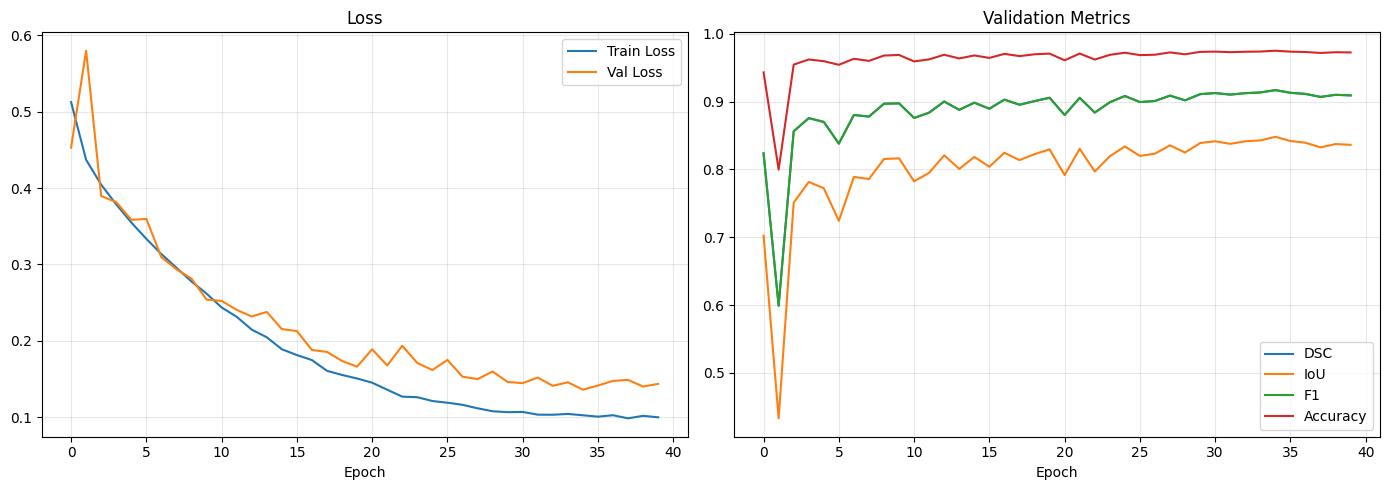

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Val Loss')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history['val_dice'], label='DSC')
axes[1].plot(history['val_iou'], label='IoU')
axes[1].plot(history['val_f1'], label='F1')
axes[1].plot(history['val_acc'], label='Accuracy')
axes[1].set_title('Validation Metrics'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 12. Final evaluation on the held-out test set

In [ ]:
model.load_state_dict(torch.load(cfg.ckpt_path, map_location=device))
model.eval()

test_loss, test_metrics = run_epoch(test_loader, train=False)

print("=" * 50)
print("FINAL TEST SET RESULTS — TransUNet on Kvasir-SEG")
print("=" * 50)
print(f"DSC (Dice Similarity Coefficient) : {test_metrics['dice']:.4f}")
print(f"IoU (Intersection over Union)     : {test_metrics['iou']:.4f}")
print(f"F1 Score                          : {test_metrics['f1']:.4f}")
print(f"Pixel Accuracy                    : {test_metrics['accuracy']:.4f}")
print(f"Precision                         : {test_metrics['precision']:.4f}")
print(f"Recall                            : {test_metrics['recall']:.4f}")
print("=" * 50)


FINAL TEST SET RESULTS — TransUNet on Kvasir-SEG
DSC (Dice Similarity Coefficient) : 0.8954
IoU (Intersection over Union)     : 0.8173
F1 Score                          : 0.8954
Pixel Accuracy                    : 0.9691


KeyError: 'precision'

## 13. Qualitative results — visualize predictions

In [ ]:
@torch.no_grad()
def visualize_predictions(loader, n=4):
    model.eval()
    images, masks = next(iter(loader))
    images, masks = images.to(device), masks.to(device)
    logits = model(images)
    preds = (torch.sigmoid(logits) > cfg.threshold).float()

    mean = np.array([0.485, 0.456, 0.406]); std = np.array([0.229, 0.224, 0.225])
    n = min(n, images.size(0))
    fig, axes = plt.subplots(n, 3, figsize=(9, 3 * n))
    if n == 1:
        axes = axes[None, :]

    for i in range(n):
        img = images[i].cpu().permute(1, 2, 0).numpy() * std + mean
        img = img.clip(0, 1)
        axes[i, 0].imshow(img); axes[i, 0].set_title('Image'); axes[i, 0].axis('off')
        axes[i, 1].imshow(masks[i].cpu().squeeze(), cmap='gray'); axes[i, 1].set_title('Ground Truth'); axes[i, 1].axis('off')
        axes[i, 2].imshow(preds[i].cpu().squeeze(), cmap='gray'); axes[i, 2].set_title('Prediction'); axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()

visualize_predictions(test_loader, n=4)


## Notes / ways to extend this notebook

- **Speed vs. accuracy**: reduce `cfg.epochs` for a quick run, or increase `transformer_layers`
  / switch to a larger ResNet backbone for higher accuracy at the cost of training time.
- **Threshold tuning**: `cfg.threshold` controls the binarization cutoff used for all metrics;
  sweep it (e.g. 0.3–0.7) on the validation set to squeeze out extra performance.
- **K-fold cross-validation**: wrap the train/val/test split and training loop in a loop over
  folds if you want more robust reported metrics.
- **Original TransUNet paper**: Chen et al., *"TransUNet: Transformers Make Strong Encoders for
  Medical Image Segmentation"*, 2021. Official repo: https://github.com/Beckschen/TransUNet
  (built for Synapse/ACDC multi-class segmentation with its own config system — this notebook
  reimplements the same architecture in a compact, self-contained way for binary polyp
  segmentation on Kvasir-SEG so you can edit it freely).
